# EDA 02 — SustainableFoodDB Carbon Analysis

This notebook consolidates the work previously split across:
- `03_carbon_audit.py` — source-data quality audit and mapping review flags.
- `04_carbon_impact.py` — carbon evidence for exploratory ingredient candidate pairs.
- The earlier `eda_02_carbon.ipynb` — descriptive statistics, top-ingredient tables, and distributions.

## Input and output locations

**Primary dataset input**
```text
BTP_2/dataset/processed/SustainableFoodDB_CarbonFootprints.csv
```

**Optional candidate-pair input** (generated by the GastroGraph embedding workflow)
```text
BTP_2/GastroGraph-custom/data/embedding_nearest_neighbors.csv
```

**All notebook outputs**
```text
BTP_2/EDA/results/carbon/
```

The carbon audit and descriptive EDA run using the SustainableFoodDB CSV alone. The candidate-pair impact analysis runs only when the nearest-neighbour file is available.

## Important interpretation limits

- A nearest-neighbour pair is an exploratory candidate pair, not a validated substitute.
- `0.85` is a project review threshold for mapping similarity, not an official SustainableFoodDB cutoff.
- The CSV column names alone do not establish the unit or reference basis of `CarbonFootprint`; confirm this from the dataset documentation before making absolute environmental claims.
- The carbon score is environmental evidence only. It does not establish culinary, nutritional, or functional suitability.
- The notebook preserves raw comparisons for review and withholds the recommended score unless both ingredient mappings pass the project review checks.


## 1. Setup and path resolution

The notebook locates the project root whether it is launched from `BTP_2/`, `BTP_2/EDA/`, or another working directory inside the project. It does not write outputs into `GastroGraph-custom/data`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_MARKER = Path("dataset") / "processed" / "SustainableFoodDB_CarbonFootprints.csv"

def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in [start, *start.parents]:
        if (candidate / PROJECT_MARKER).is_file():
            return candidate
    raise FileNotFoundError(
        "Could not locate the BTP_2 project root. Expected to find "
        f"{PROJECT_MARKER} beneath the current directory or one of its parents."
    )

PROJECT_ROOT = find_project_root(Path.cwd())
DATASET_FILE = PROJECT_ROOT / PROJECT_MARKER
NEIGHBOR_CANDIDATES = [
    PROJECT_ROOT / "GastroGraph-custom" / "data" / "embedding_nearest_neighbors.csv",
    PROJECT_ROOT / "GastroGraph-custom" / "data" / "processed" / "embedding_nearest_neighbors.csv",
    PROJECT_ROOT / "dataset" / "processed" / "embedding_nearest_neighbors.csv",
]
NEIGHBOR_FILE = next((p for p in NEIGHBOR_CANDIDATES if p.is_file()), None)

OUTPUT_DIR = PROJECT_ROOT / "EDA" / "results" / "carbon"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MAPPING_REVIEW_THRESHOLD = 0.85
REQUIRED_CARBON_COLUMNS = [
    "Ingredient", "SueatableIngredient", "Similarity", "CarbonFootprint", "Count"
]

print("Project root :", PROJECT_ROOT)
print("Carbon input :", DATASET_FILE)
print("Candidate pairs:", NEIGHBOR_FILE if NEIGHBOR_FILE else "Not found — impact analysis will be skipped")
print("Output folder:", OUTPUT_DIR)


Project root : /Users/harshgupta/Coding/BTP_2
Carbon input : /Users/harshgupta/Coding/BTP_2/dataset/processed/SustainableFoodDB_CarbonFootprints.csv
Candidate pairs: /Users/harshgupta/Coding/BTP_2/GastroGraph-custom/data/embedding_nearest_neighbors.csv
Output folder: /Users/harshgupta/Coding/BTP_2/EDA/results/carbon


## 2. Load and validate the carbon dataset

The source columns are retained. Numeric fields are converted with invalid values becoming missing, so they can be counted and reviewed rather than silently discarded.


In [2]:
df = pd.read_csv(DATASET_FILE, low_memory=False)
df.columns = [str(c).strip() for c in df.columns]

missing_columns = [c for c in REQUIRED_CARBON_COLUMNS if c not in df.columns]
if missing_columns:
    raise ValueError(
        f"Carbon dataset is missing required columns: {missing_columns}. "
        f"Columns found: {df.columns.tolist()}"
    )

for col in ["Ingredient", "SueatableIngredient"]:
    df[col] = df[col].astype("string").str.strip()

for col in ["Similarity", "CarbonFootprint", "Count"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")
print("\nColumn names:")
print(df.columns.tolist())


Rows: 7,753
Columns: 5

Column names:
['Ingredient', 'SueatableIngredient', 'Similarity', 'CarbonFootprint', 'Count']


## 3. Initial data overview

In [3]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_non_missing": df.nunique(dropna=True),
})
display(overview)
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Blank Ingredient values:", int(df["Ingredient"].fillna("").eq("").sum()))
print("Blank SueatableIngredient values:", int(df["SueatableIngredient"].fillna("").eq("").sum()))
overview.to_csv(OUTPUT_DIR / "carbon_data_overview.csv", index=True)


,dtype,missing_values,missing_percent,unique_non_missing
Ingredient,string,0,0.00,7753
SueatableIngredient,string,0,0.00,266
Similarity,float64,0,0.00,7577
CarbonFootprint,float64,0,0.00,195
Count,float64,1,0.01,480


Exact duplicate rows: 0
Blank Ingredient values: 0
Blank SueatableIngredient values: 0


## 4. Descriptive statistics and distributions

The descriptive statistics are calculated for the three numeric fields used by the original EDA: `CarbonFootprint`, `Similarity`, and `Count`.


In [4]:
NUMERIC_COLUMNS = ["CarbonFootprint", "Similarity", "Count"]
numeric_stats = df[NUMERIC_COLUMNS].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
).T
numeric_stats["skewness"] = df[NUMERIC_COLUMNS].skew(numeric_only=True)
display(numeric_stats)
numeric_stats.to_csv(OUTPUT_DIR / "carbon_statistics.csv")

print("Similarity values greater than 1:")
display(df.loc[df["Similarity"].gt(1), ["Ingredient", "SueatableIngredient", "Similarity"]].head(20))
print("Total Similarity > 1:", int(df["Similarity"].gt(1).sum()))


,count,mean,std,min,25%,50%,75%,90%,95%,max,skewness
CarbonFootprint,7753.0,4.137135,5.398522,0.11,0.730000,1.80000,4.030000,11.950000,18.850000,27.720000,1.881971
Similarity,7753.0,0.869558,0.043403,0.81,0.835115,0.86145,0.895162,0.930119,0.951066,1.000001,0.889080
Count,7752.0,198.022962,1934.928639,2.00,2.000000,2.00000,12.000000,80.000000,326.000000,69096.000000,20.713095


Similarity values greater than 1:


,Ingredient,SueatableIngredient,Similarity
0,onion,ONION,1.000001
1,butter,BUTTER,1.000000
4,olive oil,OLIVE OIL,1.000000
5,egg,EGG,1.000000
10,pepper,PEPPER,1.000000
19,cream,CREAM,1.000000
20,ginger,GINGER,1.000000
24,potato,POTATO,1.000000
27,lemon,LEMON,1.000000
30,mushroom,MUSHROOM,1.000000


Total Similarity > 1: 75


In [5]:
top_by_count = df.nlargest(20, "Count")[
    ["Ingredient", "SueatableIngredient", "Count", "CarbonFootprint", "Similarity"]
]
top_by_carbon = df.nlargest(20, "CarbonFootprint")[
    ["Ingredient", "SueatableIngredient", "CarbonFootprint", "Count", "Similarity"]
]

print("Top 20 ingredients by Count:")
display(top_by_count)
print("Top 20 ingredients by CarbonFootprint:")
display(top_by_carbon)

top_by_count.to_csv(OUTPUT_DIR / "top_frequency_ingredients.csv", index=False)
top_by_carbon.to_csv(OUTPUT_DIR / "top_carbon_ingredients.csv", index=False)


Top 20 ingredients by Count:


,Ingredient,SueatableIngredient,Count,CarbonFootprint,Similarity
0,onion,ONION,69096.0,0.24,1.000001
1,butter,BUTTER,54026.0,9.90,1.000000
2,garlic clove,GARLIC,49786.0,0.67,0.930919
3,water,WATER,49546.0,0.49,1.000000
4,olive oil,OLIVE OIL,44782.0,3.84,1.000000
5,egg,EGG,43722.0,3.23,1.000000
6,sugar,BEET SUGAR,40542.0,0.89,0.858168
7,tomato,TOMATO,33250.0,0.48,1.000000
8,garlic,GARLIC,30872.0,0.67,1.000000
9,milk,CREAM,29170.0,5.34,0.811914


Top 20 ingredients by CarbonFootprint:


,Ingredient,SueatableIngredient,CarbonFootprint,Count,Similarity
1210,vegetarian beef,BEEF BONE FREE,27.72,32.0,0.838977
1943,vegetarian beef strip,BEEF BONE FREE,27.72,12.0,0.843751
2554,vegetarian beef broth,BEEF BONE FREE,27.72,6.0,0.817879
4099,single strength beef broth,BEEF BONE FREE,27.72,2.0,0.840060
5884,clear beef stock,BEEF BONE FREE,27.72,2.0,0.815204
6116,simple beef mixture,BEEF BONE FREE,27.72,2.0,0.855379
7126,beef stock neat,BEEF BONE FREE,27.72,2.0,0.825537
23,beef,BEEF WITH BONE,19.54,15348.0,0.873418
69,beef broth,BEEF WITH BONE,19.54,4604.0,0.887812
136,beef stock,BEEF WITH BONE,19.54,1840.0,0.837216


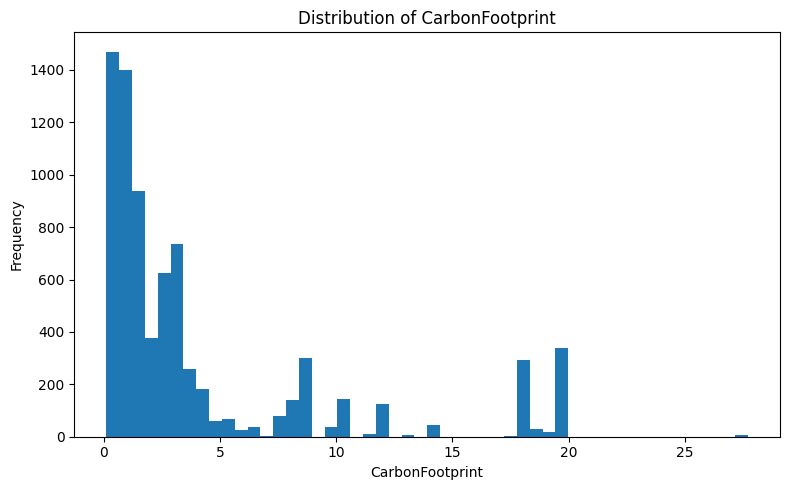

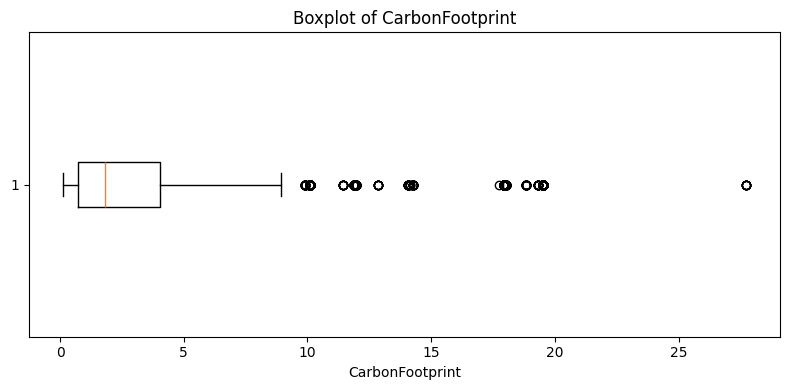

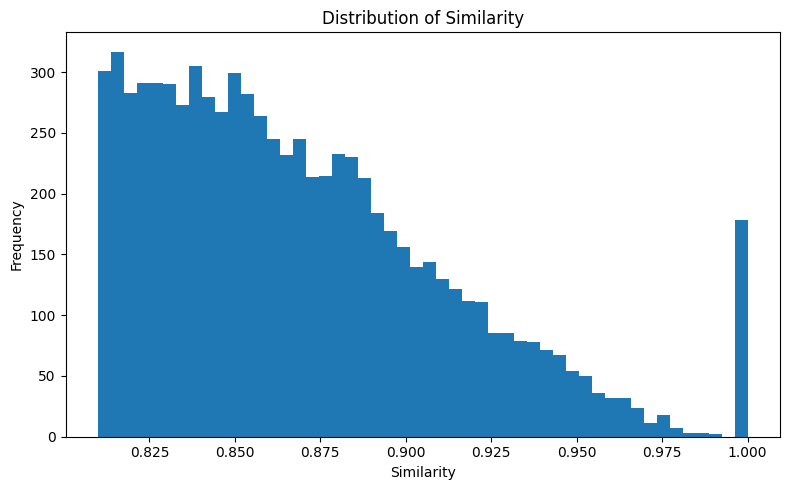

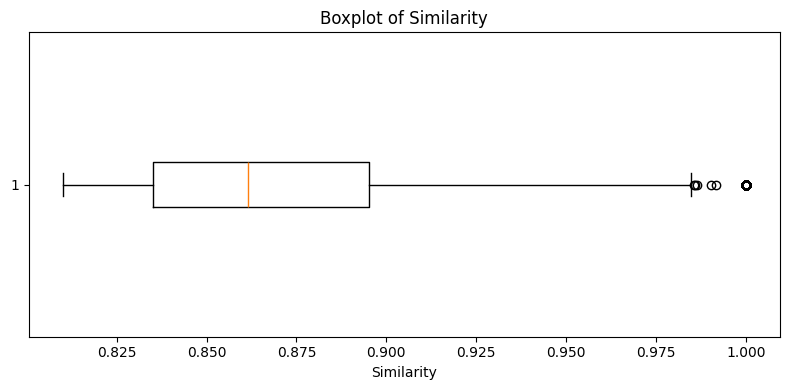

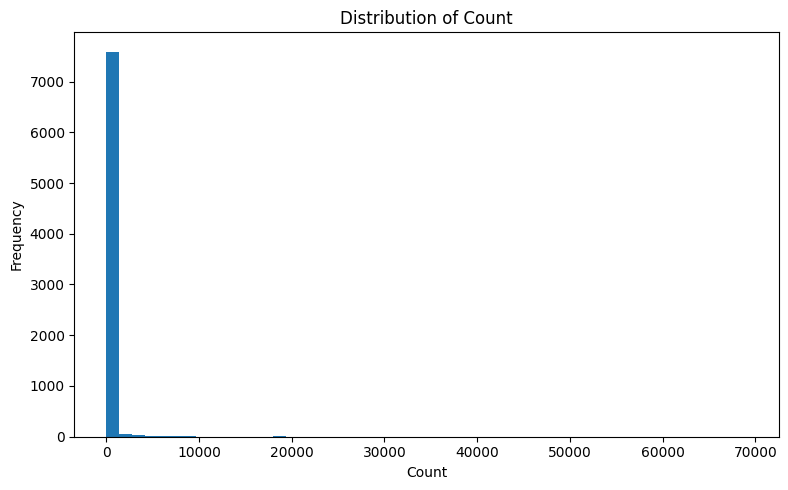

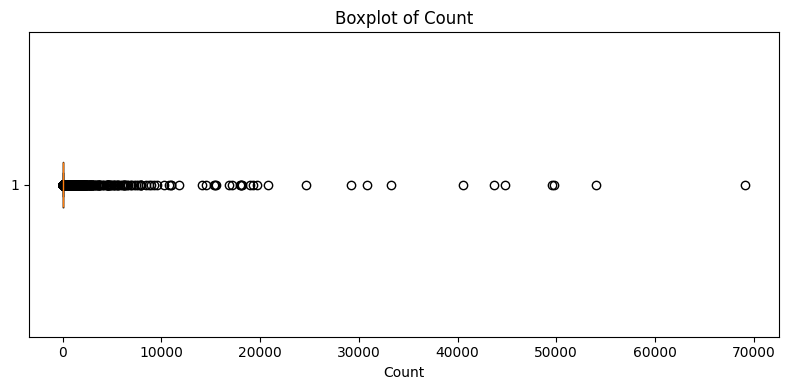

In [6]:
for col in NUMERIC_COLUMNS:
    values = df[col].dropna()
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.hist(values, bins=50)
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
    ax.set_title(f"Distribution of {col}")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{col}_distribution.png", dpi=150)
    plt.show()
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.boxplot(values, vert=False)
    ax.set_xlabel(col)
    ax.set_title(f"Boxplot of {col}")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{col}_boxplot.png", dpi=150)
    plt.show()
    plt.close(fig)


## 5. Carbon mapping audit

This section consolidates the audit in `03_carbon_audit.py`. It checks completeness, duplicates, numeric validity, mapping coverage, and category-level reuse.

Review flags are diagnostic signals. They do not automatically prove that a mapping is wrong or remove the affected row.


In [7]:
missing_by_column = df[REQUIRED_CARBON_COLUMNS].isna().sum()
blank_ingredient = int(df["Ingredient"].fillna("").eq("").sum())
blank_sustainable = int(df["SueatableIngredient"].fillna("").eq("").sum())

exact_duplicate_rows = int(df.duplicated().sum())
duplicate_ingredient_rows = int(df.duplicated(subset=["Ingredient"], keep=False).sum())
duplicate_mapping_rows = int(
    df.duplicated(subset=["Ingredient", "SueatableIngredient"], keep=False).sum()
)

similarity = df["Similarity"]
carbon = df["CarbonFootprint"]
count = df["Count"]

similarity_outside_range = int(((similarity < 0) | (similarity > 1.00001)).sum())
tiny_similarity_over_one = int(((similarity > 1) & (similarity <= 1.00001)).sum())
negative_carbon = int((carbon < 0).sum())
negative_count = int((count < 0).sum())
nonfinite_numeric = {
    col: int((~np.isfinite(df[col].dropna())).sum())
    for col in ["Similarity", "CarbonFootprint", "Count"]
}

unique_ingredients = int(df["Ingredient"].nunique(dropna=True))
unique_sustainable = int(df["SueatableIngredient"].nunique(dropna=True))

valid_mapping_rows = df.dropna(subset=["Ingredient", "SueatableIngredient"])
one_to_many = valid_mapping_rows.groupby("Ingredient")["SueatableIngredient"].nunique()
many_to_one = valid_mapping_rows.groupby("SueatableIngredient")["Ingredient"].nunique()

print("COMPLETENESS")
for col, value in missing_by_column.items():
    print(f"Missing {col}: {int(value):,}")
print(f"Blank Ingredient values: {blank_ingredient:,}")
print(f"Blank SueatableIngredient values: {blank_sustainable:,}")

print("\nDUPLICATES")
print(f"Exact duplicate rows: {exact_duplicate_rows:,}")
print(f"Rows belonging to duplicated Ingredient values: {duplicate_ingredient_rows:,}")
print(f"Rows belonging to duplicated Ingredient + SueatableIngredient pairs: {duplicate_mapping_rows:,}")

print("\nCOVERAGE")
print(f"Unique source ingredients: {unique_ingredients:,}")
print(f"Unique sustainable categories: {unique_sustainable:,}")
print(f"Source ingredients mapped to multiple categories: {int((one_to_many > 1).sum()):,}")
print(f"Sustainable categories mapped from multiple source ingredients: {int((many_to_one > 1).sum()):,}")

print("\nNUMERIC VALIDATION")
print(f"Similarity outside [0, 1.00001]: {similarity_outside_range:,}")
print(f"Tiny floating-point similarity values > 1 and <= 1.00001: {tiny_similarity_over_one:,}")
print(f"Negative carbon-footprint values: {negative_carbon:,}")
print(f"Negative Count values: {negative_count:,}")
print("Non-finite values among non-missing numeric values:", nonfinite_numeric)


COMPLETENESS
Missing Ingredient: 0
Missing SueatableIngredient: 0
Missing Similarity: 0
Missing CarbonFootprint: 0
Missing Count: 1
Blank Ingredient values: 0
Blank SueatableIngredient values: 0

DUPLICATES
Exact duplicate rows: 0
Rows belonging to duplicated Ingredient values: 0
Rows belonging to duplicated Ingredient + SueatableIngredient pairs: 0

COVERAGE
Unique source ingredients: 7,753
Unique sustainable categories: 266
Source ingredients mapped to multiple categories: 0
Sustainable categories mapped from multiple source ingredients: 249

NUMERIC VALIDATION
Similarity outside [0, 1.00001]: 0
Tiny floating-point similarity values > 1 and <= 1.00001: 75
Negative carbon-footprint values: 0
Negative Count values: 0
Non-finite values among non-missing numeric values: {'Similarity': 0, 'CarbonFootprint': 0, 'Count': 0}


In [8]:
review = df.copy()
review["audit_flag"] = ""

def add_flag(mask, label):
    review.loc[mask.fillna(False), "audit_flag"] += label + ";"

add_flag(review["Ingredient"].isna() | review["Ingredient"].eq(""), "MISSING_INGREDIENT")
add_flag(
    review["SueatableIngredient"].isna() | review["SueatableIngredient"].eq(""),
    "MISSING_SUSTAINABLE_INGREDIENT",
)
add_flag(review["Similarity"].isna(), "MISSING_SIMILARITY")
add_flag(review["Similarity"].lt(MAPPING_REVIEW_THRESHOLD), f"LOW_SIMILARITY_LT_{MAPPING_REVIEW_THRESHOLD}")
add_flag(
    review["Similarity"].lt(0) | review["Similarity"].gt(1.00001),
    "INVALID_SIMILARITY_RANGE",
)
add_flag(review["CarbonFootprint"].isna(), "MISSING_CARBON_FOOTPRINT")
add_flag(review["CarbonFootprint"].lt(0), "NEGATIVE_CARBON_FOOTPRINT")
add_flag(review["Count"].isna(), "MISSING_COUNT")
add_flag(review["Count"].lt(0), "NEGATIVE_COUNT")

flagged = review.loc[review["audit_flag"].ne("")].copy()

category_summary = (
    df.groupby("SueatableIngredient", dropna=False)
    .agg(
        source_ingredient_count=("Ingredient", "nunique"),
        row_count=("Ingredient", "size"),
        carbon_footprint_min=("CarbonFootprint", "min"),
        carbon_footprint_max=("CarbonFootprint", "max"),
        similarity_mean=("Similarity", "mean"),
        count_sum=("Count", "sum"),
    )
    .reset_index()
    .sort_values(["source_ingredient_count", "row_count"], ascending=False)
)

review.to_csv(OUTPUT_DIR / "carbon_audit_full.csv", index=False)
flagged.to_csv(OUTPUT_DIR / "carbon_audit_review_flags.csv", index=False)
category_summary.to_csv(OUTPUT_DIR / "carbon_audit_category_summary.csv", index=False)

print(f"Rows flagged for review: {len(flagged):,} of {len(review):,}")
print(f"Project mapping review threshold: {MAPPING_REVIEW_THRESHOLD}")
display(flagged.head(20))
display(category_summary.head(20))


Rows flagged for review: 3,052 of 7,753
Project mapping review threshold: 0.85


,Ingredient,SueatableIngredient,Similarity,CarbonFootprint,Count,audit_flag
9,milk,CREAM,0.811914,5.34,29170.0,LOW_SIMILARITY_LT_0.85;
11,salt pepper,PEPPER,0.824522,0.58,20774.0,LOW_SIMILARITY_LT_0.85;
13,cinnamon,VANILLA,0.813387,4.30,19248.0,LOW_SIMILARITY_LT_0.85;
16,purpose flour,MILLET FLOUR,0.849839,1.37,18046.0,LOW_SIMILARITY_LT_0.85;
28,lime juice,LIME,0.814058,0.22,10956.0,LOW_SIMILARITY_LT_0.85;
35,nutmeg,CASHEW NUT,0.845771,1.56,8486.0,LOW_SIMILARITY_LT_0.85;
39,red bell pepper,RED CHILLI,0.840906,0.80,7820.0,LOW_SIMILARITY_LT_0.85;
41,coriander,RADISH,0.829282,0.15,7412.0,LOW_SIMILARITY_LT_0.85;
42,chicken,CHICKEN WITH BONE,0.823521,3.25,7178.0,LOW_SIMILARITY_LT_0.85;
49,turmeric,RADISH,0.820606,0.15,6216.0,LOW_SIMILARITY_LT_0.85;


,SueatableIngredient,source_ingredient_count,row_count,carbon_footprint_min,carbon_footprint_max,similarity_mean,count_sum
20,BEEF WITH BONE,338,338,19.54,19.54,0.859992,33984.0
53,CHICKEN WITH BONE,297,297,3.25,3.25,0.852050,48798.0
49,CHEESE SEMIHARD,283,283,8.65,8.65,0.852524,46802.0
185,PORK SAUSAGE,242,242,17.94,17.94,0.872720,7856.0
56,CHOCOLATE CREAM COOKY,190,190,1.69,1.69,0.872355,1932.0
71,CRANBERRY JUICE,173,173,2.88,2.88,0.864872,2240.0
103,GREEN BEAN,153,153,0.73,0.73,0.863976,41546.0
107,HAKE,141,141,10.12,10.12,0.848851,8624.0
68,CORNFLAKES CEREAL,133,133,2.64,2.64,0.862787,4342.0
31,BREAD WHOLE,124,124,0.78,0.78,0.867514,10410.0


## 6. Candidate-pair carbon evidence (optional)

This section consolidates `04_carbon_impact.py`. It uses `embedding_nearest_neighbors.csv` if present. The neighbour file is an upstream graph output, not a second raw SustainableFoodDB dataset.

The join is based on case- and whitespace-normalized ingredient names. If normalization creates duplicate keys in the carbon lookup, those keys are excluded from the lookup rather than selecting a mapping arbitrarily.

Raw comparisons are retained for audit. The recommended `carbon_impact_score` is populated only when both mappings pass the project's `0.85` review threshold and both carbon values are available.


In [9]:
def normalize_names(series: pd.Series) -> pd.Series:
    return (
        series.astype("string")
        .str.strip()
        .str.casefold()
        .str.replace(r"\\s+", " ", regex=True)
    )

impact_summary_lines = []
impact_ran = False

if NEIGHBOR_FILE is None:
    print("Skipping candidate-pair impact analysis: embedding_nearest_neighbors.csv was not found.")
    print("The descriptive EDA and carbon mapping audit above have still completed.")
else:
    neighbors = pd.read_csv(NEIGHBOR_FILE, low_memory=False)
    required_neighbor_columns = [
        "query_ingredient", "neighbor_ingredient", "rank", "cosine_similarity"
    ]
    missing_neighbor_columns = [
        c for c in required_neighbor_columns if c not in neighbors.columns
    ]
    if missing_neighbor_columns:
        raise ValueError(
            f"Nearest-neighbour file is missing columns: {missing_neighbor_columns}. "
            f"Columns found: {neighbors.columns.tolist()}"
        )

    carbon_lookup = df.copy()
    carbon_lookup["ingredient_key"] = normalize_names(carbon_lookup["Ingredient"])
    carbon_lookup["mapping_similarity_raw"] = carbon_lookup["Similarity"]
    carbon_lookup["mapping_similarity_clean"] = carbon_lookup["Similarity"].clip(0, 1)

    carbon_lookup["mapping_review_status"] = np.select(
        [
            (carbon_lookup["Ingredient"].isna() | carbon_lookup["Ingredient"].eq("")).fillna(False),
            (carbon_lookup["SueatableIngredient"].isna() | carbon_lookup["SueatableIngredient"].eq("")).fillna(False),
            carbon_lookup["CarbonFootprint"].isna().fillna(False),
            carbon_lookup["mapping_similarity_raw"].isna().fillna(False),
            ((carbon_lookup["mapping_similarity_raw"] < 0)
             | (carbon_lookup["mapping_similarity_raw"] > 1.00001)).fillna(False),
            (carbon_lookup["mapping_similarity_clean"] < MAPPING_REVIEW_THRESHOLD).fillna(False),
        ],
        [
            "MISSING_SOURCE_INGREDIENT",
            "MISSING_SUSTAINABLE_INGREDIENT",
            "MISSING_CARBON_VALUE",
            "MISSING_MAPPING_SIMILARITY",
            "INVALID_MAPPING_SIMILARITY",
            "REVIEW_LOW_MAPPING_SIMILARITY",
        ],
        default="MAPPING_PASSES_PROJECT_REVIEW_THRESHOLD",
    )

    duplicate_key_mask = carbon_lookup["ingredient_key"].duplicated(keep=False)
    collision_keys = set(carbon_lookup.loc[duplicate_key_mask, "ingredient_key"].dropna())
    carbon_lookup["normalized_name_collision"] = carbon_lookup["ingredient_key"].isin(collision_keys)
    carbon_lookup.to_csv(OUTPUT_DIR / "carbon_ingredient_lookup.csv", index=False)

    lookup = carbon_lookup.loc[~carbon_lookup["normalized_name_collision"]].copy()
    lookup = lookup[
        [
            "ingredient_key", "Ingredient", "SueatableIngredient", "CarbonFootprint",
            "Similarity", "mapping_similarity_clean", "mapping_review_status",
        ]
    ]

    lookup_a = lookup.rename(columns={
        "ingredient_key": "query_key",
        "Ingredient": "carbon_source_name_a",
        "SueatableIngredient": "sustainable_category_a",
        "CarbonFootprint": "carbon_footprint_a",
        "Similarity": "mapping_similarity_raw_a",
        "mapping_similarity_clean": "mapping_similarity_a",
        "mapping_review_status": "mapping_status_a",
    })
    lookup_b = lookup.rename(columns={
        "ingredient_key": "neighbor_key",
        "Ingredient": "carbon_source_name_b",
        "SueatableIngredient": "sustainable_category_b",
        "CarbonFootprint": "carbon_footprint_b",
        "Similarity": "mapping_similarity_raw_b",
        "mapping_similarity_clean": "mapping_similarity_b",
        "mapping_review_status": "mapping_status_b",
    })

    neighbors = neighbors.copy()
    for col in ["query_ingredient", "neighbor_ingredient"]:
        neighbors[col] = neighbors[col].astype("string").str.strip()
    neighbors["rank"] = pd.to_numeric(neighbors["rank"], errors="coerce")
    neighbors["cosine_similarity"] = pd.to_numeric(neighbors["cosine_similarity"], errors="coerce")
    neighbors["query_key"] = normalize_names(neighbors["query_ingredient"])
    neighbors["neighbor_key"] = normalize_names(neighbors["neighbor_ingredient"])

    evidence = neighbors.merge(lookup_a, on="query_key", how="left")
    evidence = evidence.merge(lookup_b, on="neighbor_key", how="left")

    cf_a = evidence["carbon_footprint_a"]
    cf_b = evidence["carbon_footprint_b"]
    both_carbon_available = cf_a.notna() & cf_b.notna()
    both_mappings_pass = (
        evidence["mapping_similarity_a"].ge(MAPPING_REVIEW_THRESHOLD)
        & evidence["mapping_similarity_b"].ge(MAPPING_REVIEW_THRESHOLD)
        & evidence["mapping_status_a"].eq("MAPPING_PASSES_PROJECT_REVIEW_THRESHOLD")
        & evidence["mapping_status_b"].eq("MAPPING_PASSES_PROJECT_REVIEW_THRESHOLD")
    )
    score_eligible = both_carbon_available & both_mappings_pass

    evidence["carbon_saving_absolute_raw"] = np.where(
        both_carbon_available, cf_a - cf_b, np.nan
    )
    evidence["carbon_reduction_percent_raw"] = np.where(
        both_carbon_available & cf_a.gt(0), (cf_a - cf_b) / cf_a * 100.0, np.nan
    )
    max_footprint = pd.concat([cf_a, cf_b], axis=1).max(axis=1)
    evidence["carbon_impact_score_raw"] = np.where(
        both_carbon_available & max_footprint.gt(0),
        (cf_a - cf_b) / max_footprint,
        np.nan,
    )

    evidence["carbon_impact_score"] = evidence["carbon_impact_score_raw"].where(score_eligible, np.nan)
    evidence["carbon_saving_absolute"] = evidence["carbon_saving_absolute_raw"].where(score_eligible, np.nan)
    evidence["carbon_reduction_percent"] = evidence["carbon_reduction_percent_raw"].where(score_eligible, np.nan)

    evidence["carbon_evidence_status"] = np.select(
        [
            ~both_carbon_available,
            both_carbon_available & ~both_mappings_pass,
            score_eligible & cf_a.eq(cf_b),
            score_eligible & cf_b.lt(cf_a),
            score_eligible & cf_b.gt(cf_a),
        ],
        [
            "CARBON_MAPPING_UNAVAILABLE",
            "MAPPING_REQUIRES_REVIEW_SCORE_WITHHELD",
            "EQUAL_RECORDED_FOOTPRINTS",
            "LOWER_RECORDED_FOOTPRINT_CANDIDATE_UNVALIDATED",
            "HIGHER_RECORDED_FOOTPRINT_CANDIDATE_UNVALIDATED",
        ],
        default="REVIEW",
    )
    evidence["candidate_validity"] = "NOT_VALIDATED_BY_CARBON"
    evidence["embedding_similarity_interpretation"] = (
        "Context only; existing diagnostics warn of potential embedding collapse."
    )
    evidence["carbon_unit_reference_basis"] = "NOT_CONFIRMED"

    evidence = evidence.sort_values(["query_ingredient", "rank"], kind="stable")
    unmatched = evidence.loc[~both_carbon_available].copy()

    evidence.to_csv(OUTPUT_DIR / "carbon_impact_evidence.csv", index=False)
    unmatched.to_csv(OUTPUT_DIR / "carbon_impact_unmatched_pairs.csv", index=False)

    score_count = int(evidence["carbon_impact_score"].notna().sum())
    raw_count = int(evidence["carbon_impact_score_raw"].notna().sum())
    pairs_with_both = int(both_carbon_available.sum())
    pairs_missing = int((~both_carbon_available).sum())
    pairs_review = int((both_carbon_available & ~both_mappings_pass).sum())
    pairs_eligible = int(score_eligible.sum())

    impact_summary_lines = [
        "CARBON IMPACT EVIDENCE SUMMARY",
        "=" * 36,
        f"Carbon input: {DATASET_FILE}",
        f"Candidate-pair input: {NEIGHBOR_FILE}",
        f"Candidate pairs: {len(evidence):,}",
        f"Pairs with both carbon values: {pairs_with_both:,}",
        f"Pairs missing at least one carbon value: {pairs_missing:,}",
        f"Pairs with both mappings passing project threshold: {pairs_eligible:,}",
        f"Pairs with raw score available (for review only): {raw_count:,}",
        f"Pairs with recommended carbon_impact_score populated: {score_count:,}",
        f"Pairs requiring mapping review: {pairs_review:,}",
        f"Normalized ingredient-name collisions excluded from lookup: {len(collision_keys):,}",
        "",
        "SCORE:",
        "carbon_impact_score = (CF_A - CF_B) / max(CF_A, CF_B)",
        "Positive: B has a lower recorded footprint; zero: equal; negative: B is higher.",
        "The recommended score is withheld unless both mappings pass the project review threshold.",
        "",
        "LIMITATIONS:",
        "1. Nearest neighbours are exploratory candidates, not validated substitutes.",
        "2. Mapping threshold 0.85 is a project review rule, not an official dataset cutoff.",
        "3. Carbon-footprint unit/reference basis is not confirmed from the CSV columns alone.",
        "4. Embedding similarity is context only; existing diagnostics warn of potential embedding collapse.",
        "5. A carbon score measures environmental evidence only, not culinary or nutritional suitability.",
    ]
    (OUTPUT_DIR / "carbon_impact_summary.txt").write_text(
        "\n".join(impact_summary_lines) + "\n", encoding="utf-8"
    )

    impact_ran = True
    print("Candidate pairs:", f"{len(evidence):,}")
    print("Pairs with both carbon values:", f"{pairs_with_both:,}")
    print("Pairs missing at least one carbon value:", f"{pairs_missing:,}")
    print("Pairs passing mapping review threshold:", f"{pairs_eligible:,}")
    print("Pairs with raw score (review only):", f"{raw_count:,}")
    print("Pairs with recommended score:", f"{score_count:,}")
    print("Normalized-name collision keys excluded:", f"{len(collision_keys):,}")
    display(evidence.head(20))


Candidate pairs: 230
Pairs with both carbon values: 122
Pairs missing at least one carbon value: 108
Pairs passing mapping review threshold: 68
Pairs with raw score (review only): 122
Pairs with recommended score: 68
Normalized-name collision keys excluded: 0


,query_ingredient,neighbor_ingredient,rank,cosine_similarity,query_key,neighbor_key,carbon_source_name_a,sustainable_category_a,carbon_footprint_a,mapping_similarity_raw_a,...,carbon_saving_absolute_raw,carbon_reduction_percent_raw,carbon_impact_score_raw,carbon_impact_score,carbon_saving_absolute,carbon_reduction_percent,carbon_evidence_status,candidate_validity,embedding_similarity_interpretation,carbon_unit_reference_basis
0,beef,bay leaf,1,0.998376,beef,bay leaf,beef,BEEF WITH BONE,19.54,0.873418,...,NaN,NaN,NaN,NaN,NaN,NaN,CARBON_MAPPING_UNAVAILABLE,NOT_VALIDATED_BY_CARBON,Context only; existing diagnostics warn of pot...,NOT_CONFIRMED
1,beef,wine vinegar,2,0.997698,beef,wine vinegar,beef,BEEF WITH BONE,19.54,0.873418,...,NaN,NaN,NaN,NaN,NaN,NaN,CARBON_MAPPING_UNAVAILABLE,NOT_VALIDATED_BY_CARBON,Context only; existing diagnostics warn of pot...,NOT_CONFIRMED
2,beef,caraway seed,3,0.997573,beef,caraway seed,beef,BEEF WITH BONE,19.54,0.873418,...,NaN,NaN,NaN,NaN,NaN,NaN,CARBON_MAPPING_UNAVAILABLE,NOT_VALIDATED_BY_CARBON,Context only; existing diagnostics warn of pot...,NOT_CONFIRMED
3,beef,beef stock,4,0.997417,beef,beef stock,beef,BEEF WITH BONE,19.54,0.873418,...,0.00,0.000000,0.000000,NaN,NaN,NaN,MAPPING_REQUIRES_REVIEW_SCORE_WITHHELD,NOT_VALIDATED_BY_CARBON,Context only; existing diagnostics warn of pot...,NOT_CONFIRMED
4,beef,cod,5,0.997401,beef,cod,beef,BEEF WITH BONE,19.54,0.873418,...,16.25,83.162743,0.831627,0.831627,16.25,83.162743,LOWER_RECORDED_FOOTPRINT_CANDIDATE_UNVALIDATED,NOT_VALIDATED_BY_CARBON,Context only; existing diagnostics warn of pot...,NOT_CONFIRMED
5,beef,gruyere,6,0.997276,beef,gruyere,beef,BEEF WITH BONE,19.54,0.873418,...,11.99,61.361310,0.613613,NaN,NaN,NaN,MAPPING_REQUIRES_REVIEW_SCORE_WITHHELD,NOT_VALIDATED_BY_CARBON,Context only; existing diagnostics warn of pot...,NOT_CONFIRMED
6,beef,kefalotiri,7,0.997140,beef,kefalotiri,beef,BEEF WITH BONE,19.54,0.873418,...,9.42,48.208802,0.482088,NaN,NaN,NaN,MAPPING_REQUIRES_REVIEW_SCORE_WITHHELD,NOT_VALIDATED_BY_CARBON,Context only; existing diagnostics warn of pot...,NOT_CONFIRMED
7,beef,sauce,8,0.996916,beef,sauce,beef,BEEF WITH BONE,19.54,0.873418,...,NaN,NaN,NaN,NaN,NaN,NaN,CARBON_MAPPING_UNAVAILABLE,NOT_VALIDATED_BY_CARBON,Context only; existing diagnostics warn of pot...,NOT_CONFIRMED
8,beef,bouquet garni,9,0.996772,beef,bouquet garni,beef,BEEF WITH BONE,19.54,0.873418,...,NaN,NaN,NaN,NaN,NaN,NaN,CARBON_MAPPING_UNAVAILABLE,NOT_VALIDATED_BY_CARBON,Context only; existing diagnostics warn of pot...,NOT_CONFIRMED
9,beef,pecorino cheese,10,0.996723,beef,pecorino cheese,beef,BEEF WITH BONE,19.54,0.873418,...,10.89,55.731832,0.557318,0.557318,10.89,55.731832,LOWER_RECORDED_FOOTPRINT_CANDIDATE_UNVALIDATED,NOT_VALIDATED_BY_CARBON,Context only; existing diagnostics warn of pot...,NOT_CONFIRMED


## 7. Audit report and final output inventory

The text reports preserve the key checks and limitations. Every generated file is written under `EDA/results/carbon/`.


In [10]:
carbon_stats_text = numeric_stats.to_string()
audit_lines = [
    "SUSTAINABLEFOODDB CARBON DATA AUDIT",
    "=" * 40,
    f"Input file: {DATASET_FILE}",
    f"Rows: {len(df):,}",
    f"Columns: {len(df.columns)}",
    "",
    "COMPLETENESS",
    *[f"Missing {col}: {int(value):,}" for col, value in missing_by_column.items()],
    f"Blank Ingredient values: {blank_ingredient:,}",
    f"Blank SueatableIngredient values: {blank_sustainable:,}",
    "",
    "DUPLICATES",
    f"Exact duplicate rows: {exact_duplicate_rows:,}",
    f"Rows belonging to duplicated Ingredient values: {duplicate_ingredient_rows:,}",
    f"Rows belonging to duplicated Ingredient + SueatableIngredient pairs: {duplicate_mapping_rows:,}",
    "",
    "COVERAGE",
    f"Unique source ingredients: {unique_ingredients:,}",
    f"Unique SueatableIngredient categories: {unique_sustainable:,}",
    f"Source ingredients mapped to multiple categories: {int((one_to_many > 1).sum()):,}",
    f"Sustainable categories mapped from multiple source ingredients: {int((many_to_one > 1).sum()):,}",
    "",
    "NUMERIC VALIDATION",
    f"Similarity outside [0, 1.00001]: {similarity_outside_range:,}",
    f"Small floating-point similarity values > 1 and <= 1.00001: {tiny_similarity_over_one:,}",
    f"Negative carbon-footprint values: {negative_carbon:,}",
    f"Negative Count values: {negative_count:,}",
    *[f"Non-finite {col} values among non-missing values: {value:,}" for col, value in nonfinite_numeric.items()],
    "",
    "CARBON FOOTPRINT / MAPPING SIMILARITY / COUNT STATISTICS",
    carbon_stats_text,
    "",
    "REVIEW FLAGS",
    f"Rows flagged for review: {len(flagged):,}",
    f"Similarity review threshold: {MAPPING_REVIEW_THRESHOLD}",
    "Low similarity is a review signal, not proof that a mapping is incorrect.",
    "",
    "IMPORTANT LIMITATION",
    "The file's column names alone do not establish the carbon-footprint unit or reference basis.",
    "Confirm these from dataset documentation before making absolute environmental claims.",
    "This audit does not validate substitutions.",
]
(OUTPUT_DIR / "carbon_audit_summary.txt").write_text(
    "\n".join(audit_lines) + "\n", encoding="utf-8"
)

print("Notebook run complete.")
print("Outputs saved to:", OUTPUT_DIR)
print("\nFiles currently in the output folder:")
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(" -", path.name)


Notebook run complete.
Outputs saved to: /Users/harshgupta/Coding/BTP_2/EDA/results/carbon

Files currently in the output folder:
 - .DS_Store
 - CarbonFootprint_boxplot.png
 - CarbonFootprint_distribution.png
 - Count_boxplot.png
 - Count_distribution.png
 - Similarity_boxplot.png
 - Similarity_distribution.png
 - carbon_audit_category_summary.csv
 - carbon_audit_full.csv
 - carbon_audit_review_flags.csv
 - carbon_audit_summary.txt
 - carbon_data_overview.csv
 - carbon_impact_evidence.csv
 - carbon_impact_summary.txt
 - carbon_impact_unmatched_pairs.csv
 - carbon_ingredient_lookup.csv
 - carbon_statistics.csv
 - top_carbon_ingredients.csv
 - top_frequency_ingredients.csv
